# How Uneven Is the World's Urban Population?

**Research question.** Rank the world's cities by population: how concentrated is urban population in a few countries and a few very large cities, and does the size distribution follow the rank-size ("Zipf") pattern that urban economists expect?

**Data.** GeoNames `cities15000` - all populated places with population >= 15,000 - from <https://download.geonames.org/export/dump/> (CC BY 4.0). This notebook uses the 12,392 places with population >= 50,000 in `../data/world_cities_pop_50k.csv`.

**Tools.** Python 3, pandas, numpy, matplotlib.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 200,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.labelsize": 10.5, "font.size": 10.5,
})

df = pd.read_csv("../data/world_cities_pop_50k.csv")
df = df.rename(columns={"Country_Code": "iso2"})
df = df.dropna(subset=["Latitude", "Longitude", "Population"])
df = df.drop_duplicates(subset=["City", "Country", "Population"])
df["Population"] = df["Population"].astype(int)
df = df.sort_values("Population", ascending=False).reset_index(drop=True)

print(f"{len(df):,} places in {df.Country.nunique()} countries/territories")
print(f"total population covered: {df.Population.sum()/1e9:.2f} billion")
df.head()

12,386 places in 187 countries/territories
total population covered: 3.49 billion


,City,Country,iso2,Latitude,Longitude,Population
0,Shanghai,China,CN,31.2222,121.4581,24874500
1,Chongqing,China,CN,29.5603,106.5577,22000000
2,Chengdu,China,CN,30.6667,104.0667,20937757
3,Beijing,China,CN,39.9075,116.3972,18960744
4,Guangzhou,China,CN,23.1167,113.2500,18676605


## 1. Country concentration

Summing city populations by country shows how much of the covered population sits in a handful of countries. GeoNames records city-proper population rather than metro-area population, and for some countries it also contains urban sub-units (districts), so national totals are indicative rather than official.

In [2]:
ISO_NAMES = {
    "PK": "Pakistan", "ID": "Indonesia", "NG": "Nigeria", "VN": "Vietnam",
    "PH": "Philippines", "KR": "South Korea", "EG": "Egypt", "TR": "Turkey",
    "RU": "Russia", "MX": "Mexico", "JP": "Japan", "US": "United States",
    "BR": "Brazil", "IN": "India", "CN": "China", "IR": "Iran", "TH": "Thailand",
    "BD": "Bangladesh", "DE": "Germany", "FR": "France", "GB": "United Kingdom",
}
df["country_name"] = df["Country"].map(lambda c: ISO_NAMES.get(c, c))

by_country = (
    df.groupby("country_name")
      .agg(urban_pop=("Population", "sum"),
           n_cities=("Population", "size"),
           n_mega=("Population", lambda s: (s >= 1_000_000).sum()),
           largest_city=("City", "first"))
      .sort_values("urban_pop", ascending=False)
)
by_country["share_pct"] = 100 * by_country.urban_pop / df.Population.sum()
by_country["cum_share_pct"] = by_country.share_pct.cumsum()

top15 = by_country.head(15)
top15[["urban_pop", "n_cities", "n_mega", "share_pct", "cum_share_pct"]].round(2)

,urban_pop,n_cities,n_mega,share_pct,cum_share_pct
country_name,,,,,
China,850872456,1299,187,24.38,24.38
India,294619361,1130,57,8.44,32.83
Brazil,157682291,765,15,4.52,37.34
United States,152979160,976,15,4.38,41.73
Japan,120671420,577,12,3.46,45.19
Russia,93769751,432,14,2.69,47.87
Pakistan,83433605,209,10,2.39,50.26
Mexico,80258630,230,15,2.30,52.56
Indonesia,80138392,279,16,2.30,54.86


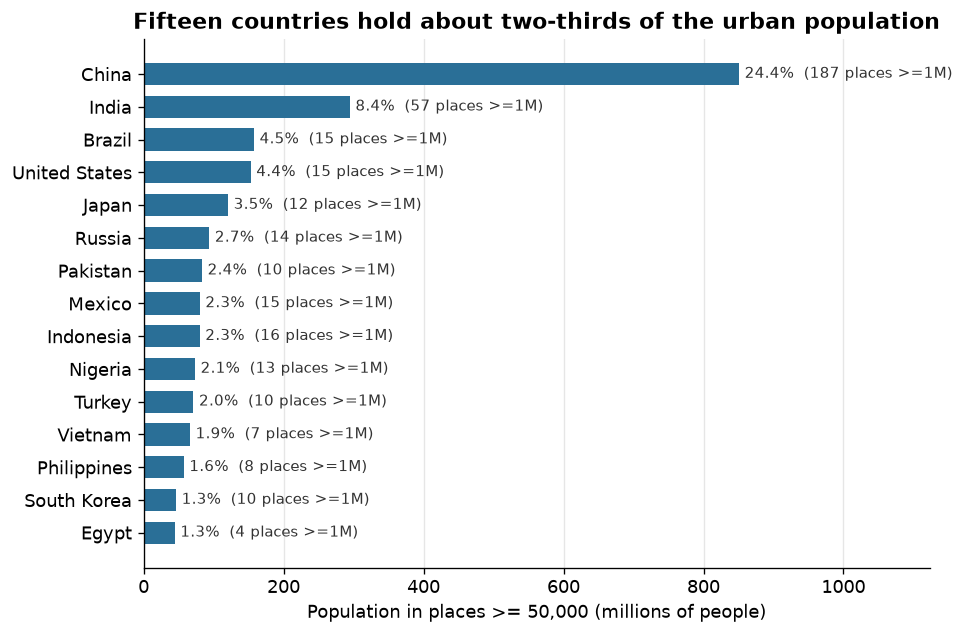

top 15 countries: 65.1% of the covered population
largest country: China, 24.4%


In [3]:
fig, ax = plt.subplots(figsize=(8.2, 5.4))
y = np.arange(len(top15))[::-1]
bars = ax.barh(y, top15.urban_pop / 1e6, color="#2A6F97", height=0.68)
for b, (_, r) in zip(bars, top15.iterrows()):
    ax.text(b.get_width() + 8, b.get_y() + b.get_height()/2,
            f"{r.share_pct:.1f}%  ({int(r.n_mega)} places >=1M)",
            va="center", fontsize=8.8, color="#333333")
ax.set_yticks(y, top15.index)
ax.set_xlim(0, top15.urban_pop.max()/1e6 * 1.32)
ax.set_xlabel("Population in places >= 50,000 (millions of people)")
ax.set_title("Fifteen countries hold about two-thirds of the urban population")
ax.grid(axis="x", color="#E6E6E6", lw=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig("../figs/fig1_top_countries.png", bbox_inches="tight")
plt.show()

print("top 15 countries: %.1f%% of the covered population" % top15.cum_share_pct.iloc[-1])
print("largest country: %s, %.1f%%" % (top15.index[0], top15.share_pct.iloc[0]))

## 2. Rank-size distribution

City-size distributions are often close to a power law: population falls roughly as 1/rank. On log-log axes that is a straight line whose slope is the Zipf exponent. A slope of -1 means the largest city is twice the size of the second, three times the third, and so on; a flatter slope means the largest cities are less dominant than that rule predicts.

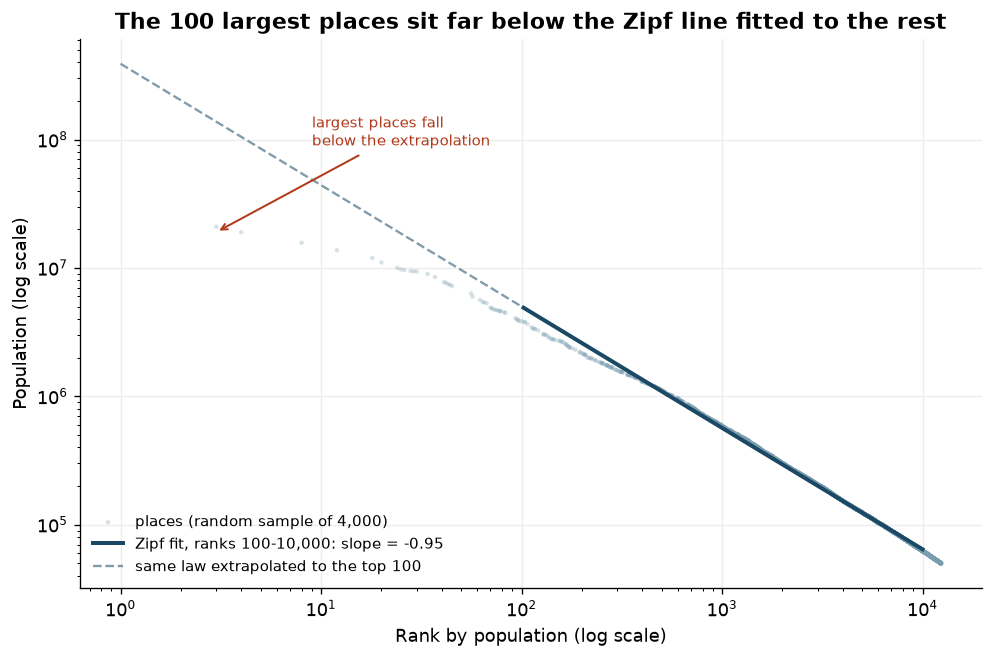

tail slope -0.95 (R2 0.998); head slope -0.49 (R2 0.934)


In [4]:
pop = df.Population.to_numpy()
ranks = np.arange(1, len(pop) + 1)

def fit(lo, hi):
    s, i = np.polyfit(np.log(ranks[lo-1:hi]), np.log(pop[lo-1:hi]), 1)
    pred = i + s * np.log(ranks[lo-1:hi])
    r2 = 1 - ((np.log(pop[lo-1:hi]) - pred) ** 2).sum() / ((np.log(pop[lo-1:hi]) - np.log(pop[lo-1:hi]).mean()) ** 2).sum()
    return s, i, r2

s_head, i_head, r2_head = fit(1, 100)
s_tail, i_tail, r2_tail = fit(100, 10000)

rng = np.random.default_rng(0)
sample = np.sort(rng.choice(len(pop), size=min(4000, len(pop)), replace=False))

fig, ax = plt.subplots(figsize=(8.4, 5.6))
ax.scatter(ranks[sample], pop[sample], s=7, alpha=0.30, color="#7A9EAF",
           edgecolors="none", label="places (random sample of 4,000)")
rr = np.logspace(0, 4, 200)
ax.plot(rr[(rr >= 100) & (rr <= 10000)], np.exp(i_tail) * rr[(rr >= 100) & (rr <= 10000)] ** s_tail,
        color="#1B4965", lw=2.4, label=f"Zipf fit, ranks 100-10,000: slope = {s_tail:.2f}")
ax.plot(rr[rr < 100], np.exp(i_tail) * rr[rr < 100] ** s_tail,
        color="#1B4965", lw=1.4, ls="--", alpha=0.55, label="same law extrapolated to the top 100")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Rank by population (log scale)")
ax.set_ylabel("Population (log scale)")
ax.set_title("The 100 largest places sit far below the Zipf line fitted to the rest")
ax.annotate("largest places fall\nbelow the extrapolation",
            xy=(3, 1.9e7), xytext=(9, 9e7),
            fontsize=9, color="#B23A1B",
            arrowprops=dict(arrowstyle="->", color="#B23A1B", lw=1.2))
ax.legend(frameon=False, loc="lower left", fontsize=9)
ax.grid(which="major", color="#EDEDED", lw=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig("../figs/fig2_rank_size.png", bbox_inches="tight")
plt.show()

print(f"tail slope {s_tail:.2f} (R2 {r2_tail:.3f}); head slope {s_head:.2f} (R2 {r2_head:.3f})")

## 3. Where the people actually live

The rank-size line is dominated by the largest cities, yet most residents live in much smaller places. Grouping places into size bands shows how much of the total each band carries.

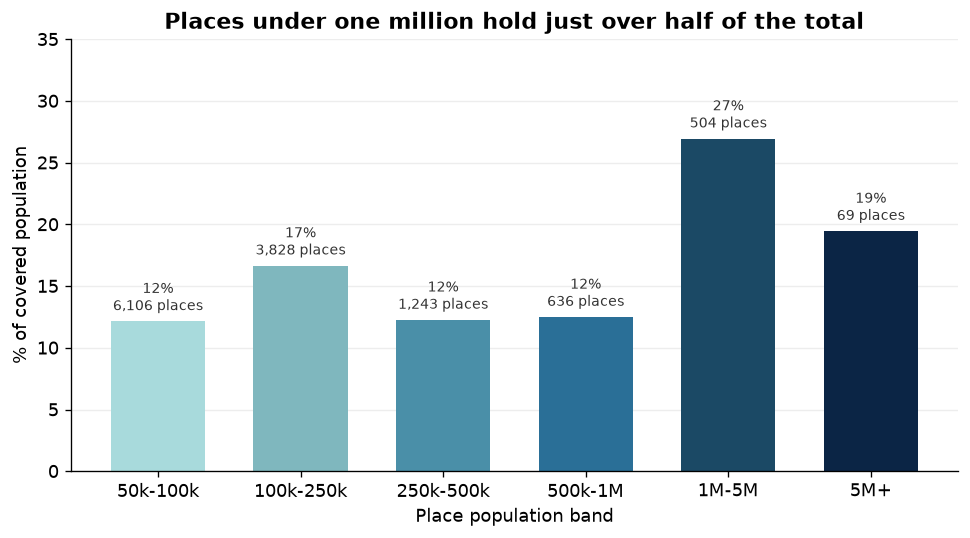

,n_cities,pop,pct_of_total
Population,,,
50k-100k,6106,424125835,12.15
100k-250k,3828,581396867,16.66
250k-500k,1243,428104976,12.27
500k-1M,636,436197542,12.50
1M-5M,504,940590593,26.95
5M+,69,679194133,19.46


In [5]:
bins = [50_000, 100_000, 250_000, 500_000, 1_000_000, 5_000_000, np.inf]
labels = ["50k-100k", "100k-250k", "250k-500k", "500k-1M", "1M-5M", "5M+"]
bands = pd.cut(df.Population, bins=bins, labels=labels, right=False)
band_stats = (df.groupby(bands, observed=True)
                .agg(n_cities=("Population", "size"), pop=("Population", "sum")))
band_stats["pct_of_total"] = 100 * band_stats["pop"] / df.Population.sum()

fig, ax = plt.subplots(figsize=(8.2, 4.6))
colors = ["#A8DADC", "#7FB7BE", "#4A8FA8", "#2A6F97", "#1B4965", "#0B2545"]
bars = ax.bar(band_stats.index.astype(str), band_stats.pct_of_total, color=colors, width=0.66)
for b, (_, r) in zip(bars, band_stats.iterrows()):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.9,
            f"{r.pct_of_total:.0f}%\n{int(r.n_cities):,} places",
            ha="center", fontsize=8.5, color="#333333")
ax.set_ylim(0, band_stats.pct_of_total.max() * 1.30)
ax.set_ylabel("% of covered population")
ax.set_xlabel("Place population band")
ax.set_title("Places under one million hold just over half of the total")
ax.grid(axis="y", color="#EDEDED", lw=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig("../figs/fig3_size_bands.png", bbox_inches="tight")
plt.show()

band_stats.round(2)

## 4. Takeaways

1. **Country concentration is extreme.** The top 15 countries account for about two thirds of the covered population, and China alone for about a quarter.
2. **The head breaks the rank-size rule.** Ranks 100-10,000 follow a power law with slope about -0.95, essentially the classic Zipf value. Extrapolated to rank 1, that law would predict a city of roughly 300 million; the real largest city (Shanghai, 24.9 million) is an order of magnitude below it. The 100 largest places are therefore much less dominant than the textbook rule predicts.
3. **The head is not the whole story.** Places below one million still hold just over half of the covered population, so an urban story told only through megacities misses most residents.

**Limitation.** GeoNames mixes city-proper figures with urban districts for some countries and only includes places above 15,000, so absolute counts - especially the number of Chinese places above one million - overstate the number of distinct cities, and no time dimension is available to study growth.

In [6]:
stats = {
    "n_places": int(len(df)),
    "n_countries": int(df.country_name.nunique()),
    "total_pop": int(df.Population.sum()),
    "share_ge_1m_pct": round(100 * df.loc[df.Population >= 1_000_000, "Population"].sum() / df.Population.sum(), 2),
    "n_ge_1m": int((df.Population >= 1_000_000).sum()),
    "top_country": str(top15.index[0]),
    "top_country_share_pct": round(float(top15.share_pct.iloc[0]), 2),
    "top15_cum_share_pct": round(float(top15.cum_share_pct.iloc[-1]), 2),
    "head_slope": round(float(s_head), 3),
    "head_r2": round(float(r2_head), 3),
    "tail_slope": round(float(s_tail), 3),
    "tail_r2": round(float(r2_tail), 3),
    "median_pop": int(df.Population.median()),
    "pop_under_1m_pct": round(100 - 100 * df.loc[df.Population >= 1_000_000, "Population"].sum() / df.Population.sum(), 2),
    "band_pct": {str(k): round(float(v), 2) for k, v in band_stats.pct_of_total.items()},
}
with open("stats.json", "w") as f:
    json.dump(stats, f, indent=2)
print(json.dumps(stats, indent=2))

{
  "n_places": 12386,
  "n_countries": 187,
  "total_pop": 3489609946,
  "share_ge_1m_pct": 46.42,
  "n_ge_1m": 573,
  "top_country": "China",
  "top_country_share_pct": 24.38,
  "top15_cum_share_pct": 65.14,
  "head_slope": -0.493,
  "head_r2": 0.934,
  "tail_slope": -0.946,
  "tail_r2": 0.998,
  "median_pop": 100899,
  "pop_under_1m_pct": 53.58,
  "band_pct": {
    "50k-100k": 12.15,
    "100k-250k": 16.66,
    "250k-500k": 12.27,
    "500k-1M": 12.5,
    "1M-5M": 26.95,
    "5M+": 19.46
  }
}
